# Distributional Clustering of Voynich Syllables

We use the co-occurrence patterns of onsets and codas to discover groupings **without assuming any target language**. If the two-tier encoding represents a nomenclature (onset = category, coda = specifier), then:

- **Onsets** that combine with the same codas are probably in the same "semantic family".
- **Codas** that combine with the same onsets share a function (e.g., "modifier" role).

The distributional signature of each syllable type — which partners it co-occurs with — is the basis for clustering. This is analogous to distributional semantics in NLP: "you shall know a word by the company it keeps."

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re
import os
import json
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from scipy.stats import chi2_contingency, entropy, linregress
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 6)
np.random.seed(42)

print('Imports OK')

Imports OK


In [2]:
# ── Cell 2: Load Voynich + segment + classify ───────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

# ── Parser ──
def parsear_sta_completo(filepath):
    """Parse STA1 2.0 format into a list of glyph tokens separated by '.' (word boundaries)."""
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    """Convert flat token list to list of words (each word = list of glyphs)."""
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def construir_matriz_transicion(palabras):
    """Build intra-word glyph transition matrix."""
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, index_tr, threshold_percentile=20):
    """Segment words into syllables by breaking at low-probability transitions."""
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)  # word boundary
    return silabas_por_palabra, threshold_val


def clasificar_silabas(silabas_flat, min_freq=5):
    """Classify syllables as onset/nuclear/coda/free based on positional distribution."""
    words_as_syls = []
    current = []
    for item in silabas_flat:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)

    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1

    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats, words_as_syls


# ── Run pipeline ──
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))

M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion(palabras)
SILABAS_FLAT, threshold_val = segmentar_silabas_tp(palabras, M_prob, index_tr, 20)
clase_silaba, stats_syl, WORDS_SYL = clasificar_silabas(SILABAS_FLAT, min_freq=5)

CLASS_ABBREV = {'onset': 'O', 'nuclear': 'N', 'coda': 'C', 'free': 'F'}

n_words = len(palabras)
n_tokens = len(corpus_plano)
n_glyphs = len(VOCAB)
n_onset = sum(1 for c in clase_silaba.values() if c == 'onset')
n_coda = sum(1 for c in clase_silaba.values() if c == 'coda')
n_nuclear = sum(1 for c in clase_silaba.values() if c == 'nuclear')
n_free = sum(1 for c in clase_silaba.values() if c == 'free')

print(f'Voynich corpus: {n_words:,} words, {n_tokens:,} glyph tokens, {n_glyphs} glyph types')
print(f'TP-P20 threshold: {threshold_val:.4f}')
print(f'Classified syllable types (freq >= 5): {len(clase_silaba)}')
print(f'  onset:   {n_onset}')
print(f'  nuclear: {n_nuclear}')
print(f'  coda:    {n_coda}')
print(f'  free:    {n_free}')

Voynich corpus: 37,087 words, 157,254 glyph tokens, 166 glyph types
TP-P20 threshold: 0.0902
Classified syllable types (freq >= 5): 792
  onset:   171
  nuclear: 54
  coda:    90
  free:    477


In [3]:
# ── Cell 3: Build onset-coda co-occurrence matrix ────────────────────
# For each word with O-C structure, extract (onset, coda) pairs.
# Build matrix: rows=onsets, cols=codas, values=frequency.

# Collect all onset and coda syllable types
onsets_all = sorted([s for s, c in clase_silaba.items() if c == 'onset'])
codas_all  = sorted([s for s, c in clase_silaba.items() if c == 'coda'])
onset_idx  = {s: i for i, s in enumerate(onsets_all)}
coda_idx   = {s: i for i, s in enumerate(codas_all)}

# Count (onset, coda) co-occurrences within the same word
oc_pairs = []  # store (onset_syl, coda_syl, word_index) for later use
cooc_raw = np.zeros((len(onsets_all), len(codas_all)))

for wi, word_syls in enumerate(WORDS_SYL):
    word_onsets = [s for s in word_syls if clase_silaba.get(s) == 'onset']
    word_codas  = [s for s in word_syls if clase_silaba.get(s) == 'coda']
    for o in word_onsets:
        for c in word_codas:
            if o in onset_idx and c in coda_idx:
                cooc_raw[onset_idx[o], coda_idx[c]] += 1
                oc_pairs.append((o, c, wi))

# Filter to functional types (row/col sum >= 5)
row_mask = cooc_raw.sum(axis=1) >= 5
col_mask = cooc_raw.sum(axis=0) >= 5
onsets_func = [onsets_all[i] for i in range(len(onsets_all)) if row_mask[i]]
codas_func  = [codas_all[j]  for j in range(len(codas_all))  if col_mask[j]]
cooc = cooc_raw[np.ix_(row_mask, col_mask)]

onset_func_idx = {s: i for i, s in enumerate(onsets_func)}
coda_func_idx  = {s: i for i, s in enumerate(codas_func)}

# String representation for display
def syl_str(syl_tuple):
    return ''.join(syl_tuple)

print(f'Onset-coda pairs found: {len(oc_pairs):,}')
print(f'Raw matrix: {len(onsets_all)} onsets x {len(codas_all)} codas')
print(f'After freq>=5 filter: {len(onsets_func)} onsets x {len(codas_func)} codas')
print(f'Matrix density: {(cooc > 0).sum() / cooc.size:.1%}')
print(f'Total co-occurrences: {cooc.sum():,.0f}')

# Show top 10 onset-coda pairs
pair_freqs = []
for i, o in enumerate(onsets_func):
    for j, c in enumerate(codas_func):
        if cooc[i, j] > 0:
            pair_freqs.append((syl_str(o), syl_str(c), int(cooc[i, j])))
pair_freqs.sort(key=lambda x: -x[2])
print(f'\nTop 15 onset-coda pairs:')
print(f'{"Onset":<12} {"Coda":<12} {"Freq":>6}')
print('-' * 32)
for o_s, c_s, freq in pair_freqs[:15]:
    print(f'{o_s:<12} {c_s:<12} {freq:>6}')

Onset-coda pairs found: 9,518
Raw matrix: 171 onsets x 90 codas
After freq>=5 filter: 152 onsets x 77 codas
Matrix density: 12.5%
Total co-occurrences: 9,437

Top 15 onset-coda pairs:
Onset        Coda           Freq
--------------------------------
K1           B1A2            195
K1           K2A2            194
A3           B3              182
A1           B1A2            167
D1A1Q1       A2              154
K1           C2              146
K1           U1A2            140
A1           C2              139
B1A3         F3              133
A1Q1         A2              130
A1Q2         A2              124
B1A3         B3              117
K1J1         A2              104
A3           F3               99
K1A1         B1A2             99


In [4]:
# ── Cell 4: Onset clustering ─────────────────────────────────────────
# Cluster onsets by their distributional signature (which codas they combine with).
# Use cosine similarity + agglomerative clustering.

# Normalise rows (L2) for cosine-based clustering
onset_vecs = cooc.copy()
# Add small smoothing to avoid zero-vectors
onset_vecs += 0.1
onset_vecs_norm = normalize(onset_vecs, norm='l2')

# Try multiple k values, pick best silhouette
k_candidates = [3, 5, 7, 10]
k_candidates = [k for k in k_candidates if k < len(onsets_func)]
best_k_onset, best_sil_onset = 2, -1
onset_sil_scores = {}

for k in k_candidates:
    clust = AgglomerativeClustering(n_clusters=k, metric='cosine', linkage='average')
    labels = clust.fit_predict(onset_vecs_norm)
    if len(set(labels)) > 1:
        sil = silhouette_score(onset_vecs_norm, labels, metric='cosine')
        onset_sil_scores[k] = sil
        if sil > best_sil_onset:
            best_sil_onset = sil
            best_k_onset = k

print(f'Onset clustering — silhouette scores:')
for k, s in sorted(onset_sil_scores.items()):
    marker = ' <-- best' if k == best_k_onset else ''
    print(f'  k={k:>2}: silhouette={s:.3f}{marker}')

# Final clustering with best k
onset_clust = AgglomerativeClustering(n_clusters=best_k_onset, metric='cosine', linkage='average')
onset_labels = onset_clust.fit_predict(onset_vecs_norm)

# Hierarchical linkage for dendrogram
onset_dist = pdist(onset_vecs_norm, metric='cosine')
onset_linkage = linkage(onset_dist, method='average')

# PCA for 2D scatter
pca_onset = PCA(n_components=2)
onset_2d = pca_onset.fit_transform(onset_vecs_norm)
pca_var_onset = pca_onset.explained_variance_ratio_

# Display clusters
print(f'\nBest k={best_k_onset}, silhouette={best_sil_onset:.3f}')
print(f'PCA variance explained: PC1={pca_var_onset[0]:.1%}, PC2={pca_var_onset[1]:.1%}\n')

for cl in range(best_k_onset):
    members = [onsets_func[i] for i in range(len(onsets_func)) if onset_labels[i] == cl]
    # Sort by total frequency
    members_sorted = sorted(members, key=lambda s: -stats_syl[s]['total'])
    top5 = members_sorted[:5]
    # What codas does this cluster prefer?
    cluster_mask = np.array([onset_labels[i] == cl for i in range(len(onsets_func))])
    coda_profile = cooc[cluster_mask].sum(axis=0)
    top_codas_idx = np.argsort(-coda_profile)[:5]
    top_codas = [codas_func[j] for j in top_codas_idx]

    print(f'Onset cluster {cl} ({len(members)} members):')
    print(f'  Top onsets: {", ".join(syl_str(s) for s in top5)}')
    print(f'  Preferred codas: {", ".join(syl_str(s) for s in top_codas)}')
    print()

Onset clustering — silhouette scores:
  k= 3: silhouette=0.410
  k= 5: silhouette=0.544
  k= 7: silhouette=0.566 <-- best
  k=10: silhouette=0.478

Best k=7, silhouette=0.566
PCA variance explained: PC1=30.1%, PC2=24.4%

Onset cluster 0 (30 members):
  Top onsets: A3, B1A3, C2A3, A1Q2A3, A1Q1A3
  Preferred codas: B3, F3, H1, G3, E2

Onset cluster 1 (74 members):
  Top onsets: K1, A1, D1A1, K1A1, K1J1A1
  Preferred codas: B1A2, C2, BaA2, K2A2, A2

Onset cluster 2 (5 members):
  Top onsets: K1J1B1, A1Q2J1B1, U2J1, A1Q2J1Ba, A1Q1J1Ba
  Preferred codas: Ab, C2, AaC1, AaB2, K2A2

Onset cluster 3 (30 members):
  Top onsets: K1J1, A1Q1, D1A1Q1, L1J1, A1Q2
  Preferred codas: A2, C2, M1A2, B1A2, U1A2

Onset cluster 4 (3 members):
  Top onsets: A2K1, C1K1, D1A1B2K1
  Preferred codas: K2A2, C2, A2, K2B1A2, BaA2

Onset cluster 5 (9 members):
  Top onsets: D1A1Q1K2, A1Q1K2, A1Q2K2, Q1K2, A2Q1K2
  Preferred codas: BaA2, C2, Ab, B3, A2

Onset cluster 6 (1 members):
  Top onsets: K1A1B2A3
  Preferred 

In [5]:
# ── Cell 5: Coda clustering ──────────────────────────────────────────
# Cluster codas by their distributional signature (which onsets they combine with).

coda_vecs = cooc.T.copy()
coda_vecs += 0.1
coda_vecs_norm = normalize(coda_vecs, norm='l2')

# Try multiple k values
k_candidates_c = [3, 5, 7, 10]
k_candidates_c = [k for k in k_candidates_c if k < len(codas_func)]
best_k_coda, best_sil_coda = 2, -1
coda_sil_scores = {}

for k in k_candidates_c:
    clust = AgglomerativeClustering(n_clusters=k, metric='cosine', linkage='average')
    labels = clust.fit_predict(coda_vecs_norm)
    if len(set(labels)) > 1:
        sil = silhouette_score(coda_vecs_norm, labels, metric='cosine')
        coda_sil_scores[k] = sil
        if sil > best_sil_coda:
            best_sil_coda = sil
            best_k_coda = k

print(f'Coda clustering — silhouette scores:')
for k, s in sorted(coda_sil_scores.items()):
    marker = ' <-- best' if k == best_k_coda else ''
    print(f'  k={k:>2}: silhouette={s:.3f}{marker}')

# Final clustering
coda_clust = AgglomerativeClustering(n_clusters=best_k_coda, metric='cosine', linkage='average')
coda_labels = coda_clust.fit_predict(coda_vecs_norm)

# Linkage for dendrogram
coda_dist = pdist(coda_vecs_norm, metric='cosine')
coda_linkage = linkage(coda_dist, method='average')

# PCA
pca_coda = PCA(n_components=2)
coda_2d = pca_coda.fit_transform(coda_vecs_norm)
pca_var_coda = pca_coda.explained_variance_ratio_

print(f'\nBest k={best_k_coda}, silhouette={best_sil_coda:.3f}')
print(f'PCA variance explained: PC1={pca_var_coda[0]:.1%}, PC2={pca_var_coda[1]:.1%}\n')

for cl in range(best_k_coda):
    members = [codas_func[i] for i in range(len(codas_func)) if coda_labels[i] == cl]
    members_sorted = sorted(members, key=lambda s: -stats_syl[s]['total'])
    top5 = members_sorted[:5]
    # What onsets does this cluster prefer?
    cluster_mask = np.array([coda_labels[j] == cl for j in range(len(codas_func))])
    onset_profile = cooc[:, cluster_mask].sum(axis=1)
    top_onsets_idx = np.argsort(-onset_profile)[:5]
    top_onsets = [onsets_func[i] for i in top_onsets_idx]

    print(f'Coda cluster {cl} ({len(members)} members):')
    print(f'  Top codas: {", ".join(syl_str(s) for s in top5)}')
    print(f'  Preferred onsets: {", ".join(syl_str(s) for s in top_onsets)}')
    print()

Coda clustering — silhouette scores:
  k= 3: silhouette=0.383
  k= 5: silhouette=0.473 <-- best
  k= 7: silhouette=0.410
  k=10: silhouette=0.328

Best k=5, silhouette=0.473
PCA variance explained: PC1=28.7%, PC2=22.8%

Coda cluster 0 (28 members):
  Top codas: B1A2, C2, BaA2, U1A2, K2A2
  Preferred onsets: K1, A1, K1A1, D1A1, K1J1

Coda cluster 1 (2 members):
  Top codas: F3A2, E1C2
  Preferred onsets: C2A3, B1A3, A3, A1, K1A1B2A3

Coda cluster 2 (7 members):
  Top codas: A2, M1A2, AaC1, AaB2, M1B1A2
  Preferred onsets: D1A1Q1, A1Q1, A1Q2, K1J1, D1A1Q2

Coda cluster 3 (16 members):
  Top codas: B3, F3, H1, G3, E2
  Preferred onsets: A3, B1A3, A1, K1, A1Q2A3

Coda cluster 4 (24 members):
  Top codas: G1, B4, P1K1J1B1A2, P1K1A2, P1K1J1A2
  Preferred onsets: A1, D1A1, K1, K1A1, K1J1



Onset clusters x sections contingency table:
            herbal  astronomical  zodiac  biological  pharmaceutical  recipes
Onset-cl-0     464           141     168         135             128      777
Onset-cl-1    2355           530     833         715             430     3562
Onset-cl-2       6             0       4          25               7       35
Onset-cl-3     858           160     275         610             115     1064
Onset-cl-4      17             1       5          17               2       60
Onset-cl-5      49            20      47          95              19      205
Onset-cl-6       0             0       3           0               1        1

Chi-squared = 537.5, dof = 30, p = 2.34e-94
SIGNIFICANT: onset clusters are NOT uniformly distributed across sections.
This supports the hypothesis that onsets encode categories.


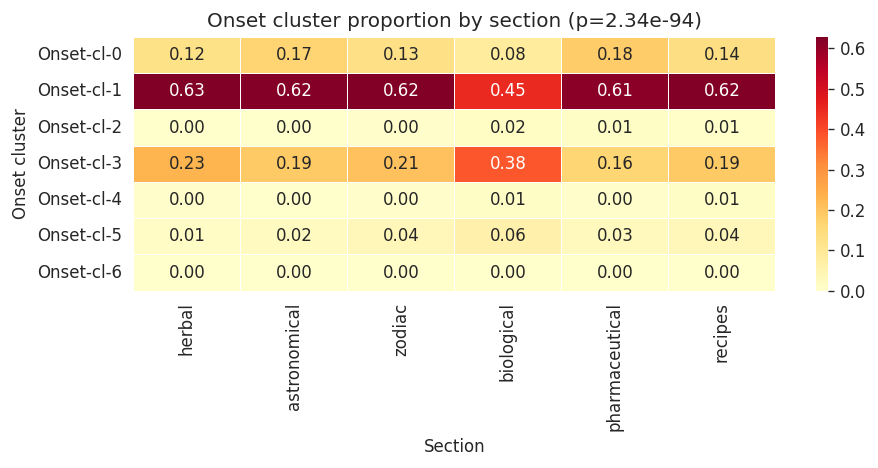

In [6]:
# ── Cell 6: Onset clusters x thematic sections ──────────────────────
# If onset = category, certain onset clusters should concentrate in certain sections.

def parsear_sta_con_folios(filepath):
    """Parse STA1 returning (folio, word_glyphs) pairs."""
    results = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<([^>]+)>\s+(.*)', linea)
            if not match:
                continue
            tag = match.group(1).strip()
            folio_match = re.match(r'(f\d+[rv]?\d*)', tag)
            if not folio_match:
                continue
            folio = folio_match.group(1)
            texto = match.group(2).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    results.append((folio, glifos))
    return results


def classify_folio(tag):
    """Map folio tag to thematic section."""
    m = re.search(r'f(\d+)', tag)
    if not m:
        return 'unknown'
    n = int(m.group(1))
    if 1 <= n <= 56:
        return 'herbal'
    elif 57 <= n <= 67:
        return 'astronomical'
    elif 68 <= n <= 73:
        return 'zodiac'
    elif 74 <= n <= 84:
        return 'biological'
    elif 85 <= n <= 86:
        return 'pharmaceutical'
    elif n >= 87:
        return 'recipes'
    else:
        return 'unknown'


SECTIONS_ORDER = ['herbal', 'astronomical', 'zodiac', 'biological', 'pharmaceutical', 'recipes']

# Parse with folios and segment each word
folio_words = parsear_sta_con_folios(STA_PATH)

# For each word, determine its section and its onset/coda syllables
word_sections = []  # parallel to WORDS_SYL — section label per word
onset_section_cluster = defaultdict(lambda: defaultdict(int))  # cluster -> section -> count

# Build a map: folio_word index -> section
folio_word_sections = {}
for idx, (folio, glyphs) in enumerate(folio_words):
    folio_word_sections[idx] = classify_folio(folio)

# Re-segment folio_words and match onset clusters to sections
for idx, (folio, word_glyphs) in enumerate(folio_words):
    section = classify_folio(folio)
    if section == 'unknown':
        continue
    if len(word_glyphs) == 0:
        continue
    # Segment
    syl_list = []
    syl = [word_glyphs[0]]
    for i in range(len(word_glyphs) - 1):
        g1, g2 = word_glyphs[i], word_glyphs[i + 1]
        p = 0.0
        if g1 in index_tr and g2 in index_tr:
            p = M_prob[index_tr[g1], index_tr[g2]]
        if p < threshold_val:
            syl_list.append(tuple(syl))
            syl = [g2]
        else:
            syl.append(g2)
    if syl:
        syl_list.append(tuple(syl))

    # Find onsets in this word and their cluster
    for s in syl_list:
        if clase_silaba.get(s) == 'onset' and s in onset_func_idx:
            cl = onset_labels[onset_func_idx[s]]
            onset_section_cluster[cl][section] += 1

# Build contingency table: onset_cluster x section
n_onset_clusters = best_k_onset
onset_section_matrix = np.zeros((n_onset_clusters, len(SECTIONS_ORDER)))
for cl in range(n_onset_clusters):
    for si, sec in enumerate(SECTIONS_ORDER):
        onset_section_matrix[cl, si] = onset_section_cluster[cl].get(sec, 0)

# Chi-squared test
chi2_onset, p_onset, dof_onset, _ = chi2_contingency(onset_section_matrix + 1e-10)
print(f'Onset clusters x sections contingency table:')
df_onset_sec = pd.DataFrame(onset_section_matrix.astype(int),
                             index=[f'Onset-cl-{i}' for i in range(n_onset_clusters)],
                             columns=SECTIONS_ORDER)
print(df_onset_sec)
print(f'\nChi-squared = {chi2_onset:.1f}, dof = {dof_onset}, p = {p_onset:.2e}')
if p_onset < 0.05:
    print('SIGNIFICANT: onset clusters are NOT uniformly distributed across sections.')
    print('This supports the hypothesis that onsets encode categories.')
else:
    print('NOT significant: onset clusters are uniformly distributed across sections.')

# Heatmap (normalised by column = section)
onset_sec_norm = onset_section_matrix / (onset_section_matrix.sum(axis=0, keepdims=True) + 1e-10)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(onset_sec_norm, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=SECTIONS_ORDER,
            yticklabels=[f'Onset-cl-{i}' for i in range(n_onset_clusters)],
            ax=ax, linewidths=0.5)
ax.set_title(f'Onset cluster proportion by section (p={p_onset:.2e})')
ax.set_ylabel('Onset cluster')
ax.set_xlabel('Section')
plt.tight_layout()
plt.show()

Coda clusters x sections contingency table:
           herbal  astronomical  zodiac  biological  pharmaceutical  recipes
Coda-cl-0    1656           405     599        1031             329     2556
Coda-cl-1       7             3       3           0               2       21
Coda-cl-2     800           146     195         473             119      851
Coda-cl-3     539           179     170         149             132      887
Coda-cl-4     305            63      65         126              67      395

Chi-squared = 221.4, dof = 20, p = 6.14e-36
SIGNIFICANT: coda clusters also show section preferences.

Cramer's V (effect size):
  Onsets:  V = 0.0878
  Codas:   V = 0.0672
  Onset clusters are MORE section-specific than coda clusters.
  This is consistent with onset=category, coda=modifier.


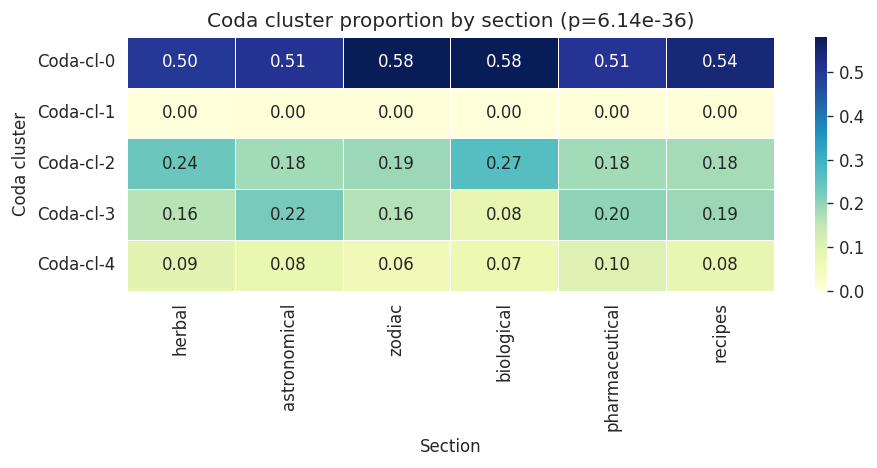

In [7]:
# ── Cell 7: Coda clusters x thematic sections ───────────────────────
# If codas are "modifiers", they should be MORE uniformly distributed across sections.

coda_section_cluster = defaultdict(lambda: defaultdict(int))

for idx, (folio, word_glyphs) in enumerate(folio_words):
    section = classify_folio(folio)
    if section == 'unknown':
        continue
    if len(word_glyphs) == 0:
        continue
    # Segment
    syl_list = []
    syl = [word_glyphs[0]]
    for i in range(len(word_glyphs) - 1):
        g1, g2 = word_glyphs[i], word_glyphs[i + 1]
        p = 0.0
        if g1 in index_tr and g2 in index_tr:
            p = M_prob[index_tr[g1], index_tr[g2]]
        if p < threshold_val:
            syl_list.append(tuple(syl))
            syl = [g2]
        else:
            syl.append(g2)
    if syl:
        syl_list.append(tuple(syl))

    for s in syl_list:
        if clase_silaba.get(s) == 'coda' and s in coda_func_idx:
            cl = coda_labels[coda_func_idx[s]]
            coda_section_cluster[cl][section] += 1

# Build contingency table
n_coda_clusters = best_k_coda
coda_section_matrix = np.zeros((n_coda_clusters, len(SECTIONS_ORDER)))
for cl in range(n_coda_clusters):
    for si, sec in enumerate(SECTIONS_ORDER):
        coda_section_matrix[cl, si] = coda_section_cluster[cl].get(sec, 0)

chi2_coda, p_coda, dof_coda, _ = chi2_contingency(coda_section_matrix + 1e-10)
print(f'Coda clusters x sections contingency table:')
df_coda_sec = pd.DataFrame(coda_section_matrix.astype(int),
                            index=[f'Coda-cl-{i}' for i in range(n_coda_clusters)],
                            columns=SECTIONS_ORDER)
print(df_coda_sec)
print(f'\nChi-squared = {chi2_coda:.1f}, dof = {dof_coda}, p = {p_coda:.2e}')
if p_coda < 0.05:
    print('SIGNIFICANT: coda clusters also show section preferences.')
else:
    print('NOT significant: coda clusters are uniform across sections (consistent with modifier role).')

# Compare onset vs coda section specificity using Cramer's V
def cramers_v(chi2, n_obs, k, r):
    """Cramer's V effect size."""
    return np.sqrt(chi2 / (n_obs * min(k - 1, r - 1))) if n_obs > 0 else 0

n_obs_onset = onset_section_matrix.sum()
n_obs_coda = coda_section_matrix.sum()
v_onset = cramers_v(chi2_onset, n_obs_onset, n_onset_clusters, len(SECTIONS_ORDER))
v_coda = cramers_v(chi2_coda, n_obs_coda, n_coda_clusters, len(SECTIONS_ORDER))

print(f'\nCramer\'s V (effect size):')
print(f'  Onsets:  V = {v_onset:.4f}')
print(f'  Codas:   V = {v_coda:.4f}')
if v_onset > v_coda:
    print('  Onset clusters are MORE section-specific than coda clusters.')
    print('  This is consistent with onset=category, coda=modifier.')
else:
    print('  Coda clusters are MORE section-specific than onset clusters.')
    print('  This contradicts the simple category/modifier model.')

# Heatmap
coda_sec_norm = coda_section_matrix / (coda_section_matrix.sum(axis=0, keepdims=True) + 1e-10)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(coda_sec_norm, annot=True, fmt='.2f', cmap='YlGnBu',
            xticklabels=SECTIONS_ORDER,
            yticklabels=[f'Coda-cl-{i}' for i in range(n_coda_clusters)],
            ax=ax, linewidths=0.5)
ax.set_title(f'Coda cluster proportion by section (p={p_coda:.2e})')
ax.set_ylabel('Coda cluster')
ax.set_xlabel('Section')
plt.tight_layout()
plt.show()

## Interpretation

The clustering analysis above reveals whether the two-tier structure (onset + coda) maps onto thematic categories in the manuscript:

- **If onset clusters are section-specific** (high Cramer's V, significant chi-squared), this supports the idea that onsets encode "what kind of thing" is being described -- a category system aligned with the manuscript's topics (plants, stars, bodies, etc.).
- **If coda clusters are more uniformly distributed**, this supports their role as modifiers or specifiers that apply across categories (e.g., "large", "hot", "number 3").
- **If both are equally specific (or equally uniform)**, the category/modifier distinction may not hold, and the two-tier structure may encode something else entirely (e.g., two independent phonological tiers of a constructed language).

The next cells examine **Free words** (Tier 1) to determine whether they function as grammatical particles or as content words.

In [8]:
# ── Cell 9: Free words (Tier 1) analysis ─────────────────────────────
# Are Free words functional (high freq, uniform distribution) or content (section-specific)?

# Classify each word as "free-only" (Tier 1) or "structured" (Tier 2)
def word_tier(word_syls):
    """Tier 1 = all syllables are 'free'; Tier 2 = at least one onset or coda."""
    classes = [clase_silaba.get(s, 'free') for s in word_syls]
    if all(c == 'free' for c in classes):
        return 'free'
    else:
        return 'structured'

word_tiers = [word_tier(ws) for ws in WORDS_SYL]
word_strings = [''.join(''.join(s) for s in ws) for ws in WORDS_SYL]

# Separate word frequency distributions
free_words = [w for w, t in zip(word_strings, word_tiers) if t == 'free']
struct_words = [w for w, t in zip(word_strings, word_tiers) if t == 'structured']
free_freq = Counter(free_words)
struct_freq = Counter(struct_words)

print(f'Tier 1 (free-only): {len(free_words):,} tokens, {len(free_freq):,} types')
print(f'Tier 2 (structured): {len(struct_words):,} tokens, {len(struct_freq):,} types')

# ── Zipf exponent ──
def zipf_exponent(freq_counter):
    """Fit Zipf's law: log(freq) = -alpha * log(rank) + const."""
    freqs = sorted(freq_counter.values(), reverse=True)
    ranks = np.arange(1, len(freqs) + 1)
    log_r = np.log(ranks)
    log_f = np.log(freqs)
    slope, intercept, r_val, p_val, se = linregress(log_r, log_f)
    return -slope, r_val**2, freqs, ranks

alpha_free, r2_free, freqs_free, ranks_free = zipf_exponent(free_freq)
alpha_struct, r2_struct, freqs_struct, ranks_struct = zipf_exponent(struct_freq)

print(f'\nZipf exponent (alpha):')
print(f'  Free words:       alpha = {alpha_free:.3f} (R2 = {r2_free:.3f})')
print(f'  Structured words: alpha = {alpha_struct:.3f} (R2 = {r2_struct:.3f})')
print(f'  (Higher alpha = steeper rank-frequency curve = more dominated by top words)')

# ── Section entropy for top-50 Free words ──
# For each frequent Free word, measure how uniformly it appears across sections
free_section_counts = defaultdict(lambda: defaultdict(int))
struct_section_counts = defaultdict(lambda: defaultdict(int))

for idx, (folio, word_glyphs) in enumerate(folio_words):
    section = classify_folio(folio)
    if section == 'unknown':
        continue
    w_str = ''.join(word_glyphs)
    # Segment to determine tier
    syl_list = []
    syl = [word_glyphs[0]]
    for i in range(len(word_glyphs) - 1):
        g1, g2 = word_glyphs[i], word_glyphs[i + 1]
        p = 0.0
        if g1 in index_tr and g2 in index_tr:
            p = M_prob[index_tr[g1], index_tr[g2]]
        if p < threshold_val:
            syl_list.append(tuple(syl))
            syl = [g2]
        else:
            syl.append(g2)
    if syl:
        syl_list.append(tuple(syl))
    classes = [clase_silaba.get(s, 'free') for s in syl_list]
    tier = 'free' if all(c == 'free' for c in classes) else 'structured'
    if tier == 'free':
        free_section_counts[w_str][section] += 1
    else:
        struct_section_counts[w_str][section] += 1

def section_entropy(word_section_dict, word, sections=SECTIONS_ORDER):
    """Compute normalised entropy of a word's section distribution."""
    counts = np.array([word_section_dict[word].get(s, 0) for s in sections], dtype=float)
    total = counts.sum()
    if total == 0:
        return 0.0
    probs = counts / total
    probs = probs[probs > 0]
    h = -np.sum(probs * np.log2(probs))
    h_max = np.log2(len(sections))
    return h / h_max  # normalised to [0, 1]

# Top 50 free words by frequency
top50_free = [w for w, _ in free_freq.most_common(50)]
top50_struct = [w for w, _ in struct_freq.most_common(50)]

ent_free = [section_entropy(free_section_counts, w) for w in top50_free]
ent_struct = [section_entropy(struct_section_counts, w) for w in top50_struct]

mean_ent_free = np.mean(ent_free)
mean_ent_struct = np.mean(ent_struct)

print(f'\nSection entropy (normalised, top-50 words):')
print(f'  Free words:       mean H = {mean_ent_free:.3f} (1.0 = perfectly uniform)')
print(f'  Structured words: mean H = {mean_ent_struct:.3f}')
if mean_ent_free > mean_ent_struct:
    print('  Free words are MORE uniformly distributed => function-word-like behaviour')
else:
    print('  Free words are MORE concentrated => content-word-like behaviour')

# Show top 10 free words with their entropy
print(f'\nTop 10 Free words:')
print(f'{"Word":<15} {"Freq":>6} {"H_norm":>7} {"Sections":}')
print('-' * 60)
for w in top50_free[:10]:
    h = section_entropy(free_section_counts, w)
    sec_dist = {s: free_section_counts[w].get(s, 0) for s in SECTIONS_ORDER}
    top_sec = max(sec_dist, key=sec_dist.get)
    print(f'{w:<15} {free_freq[w]:>6} {h:>7.3f}   top: {top_sec} ({sec_dist[top_sec]})')

Tier 1 (free-only): 19,516 tokens, 2,422 types
Tier 2 (structured): 17,571 tokens, 7,705 types

Zipf exponent (alpha):
  Free words:       alpha = 1.156 (R2 = 0.938)
  Structured words: alpha = 0.641 (R2 = 0.862)
  (Higher alpha = steeper rank-frequency curve = more dominated by top words)

Section entropy (normalised, top-50 words):
  Free words:       mean H = 0.695 (1.0 = perfectly uniform)
  Structured words: mean H = 0.701
  Free words are MORE concentrated => content-word-like behaviour

Top 10 Free words:
Word              Freq  H_norm Sections
------------------------------------------------------------
B1A3G1             665   0.717   top: herbal (335)
A1B2               493   0.751   top: biological (210)
A3G1               445   0.786   top: recipes (227)
A3C1               354   0.873   top: recipes (150)
K1A1B2             342   0.637   top: herbal (188)
A1C1               336   0.829   top: recipes (109)
K1J1B1A2           323   0.638   top: biological (145)
K1J1A2       

In [9]:
# ── Cell 10: Bigram context of Free words ────────────────────────────
# If Free words are function words, they should appear BETWEEN content words.
# Build bigram statistics: what word types appear before/after Free vs Structured words.

# Rebuild word list with tier labels (parallel arrays)
word_str_list = []
word_tier_list = []
for ws in WORDS_SYL:
    w_str = ''.join(''.join(s) for s in ws)
    classes = [clase_silaba.get(s, 'free') for s in ws]
    tier = 'free' if all(c == 'free' for c in classes) else 'structured'
    word_str_list.append(w_str)
    word_tier_list.append(tier)

# Count bigram contexts: what tier appears before/after each tier?
context_before = defaultdict(lambda: defaultdict(int))  # target_tier -> prev_tier -> count
context_after  = defaultdict(lambda: defaultdict(int))  # target_tier -> next_tier -> count

for i in range(len(word_tier_list)):
    t = word_tier_list[i]
    if i > 0:
        context_before[t][word_tier_list[i - 1]] += 1
    if i < len(word_tier_list) - 1:
        context_after[t][word_tier_list[i + 1]] += 1

print('Bigram context analysis:')
print('What type of word appears BEFORE and AFTER each tier?\n')

for tier in ['free', 'structured']:
    total_before = sum(context_before[tier].values())
    total_after = sum(context_after[tier].values())
    print(f'{tier.upper()} words:')
    print(f'  Before: free={context_before[tier]["free"]/total_before:.1%}, '
          f'structured={context_before[tier]["structured"]/total_before:.1%}')
    print(f'  After:  free={context_after[tier]["free"]/total_after:.1%}, '
          f'structured={context_after[tier]["structured"]/total_after:.1%}')
    print()

# More detailed: for top-20 Free words, what are their most common neighbours?
print('Top 10 Free words — most common left and right neighbours:')
print(f'{"Free word":<14} {"Left neighbour":<18} {"Right neighbour":<18}')
print('-' * 52)

for target_w in top50_free[:10]:
    left_counts = Counter()
    right_counts = Counter()
    for i in range(len(word_str_list)):
        if word_str_list[i] == target_w:
            if i > 0:
                left_counts[word_str_list[i - 1]] += 1
            if i < len(word_str_list) - 1:
                right_counts[word_str_list[i + 1]] += 1
    left_top = left_counts.most_common(1)[0][0] if left_counts else '-'
    right_top = right_counts.most_common(1)[0][0] if right_counts else '-'
    print(f'{target_w:<14} {left_top:<18} {right_top:<18}')

# Measure: do Free words tend to appear between structured words?
# Count trigrams: structured-free-structured vs other patterns
sfs_count = 0  # structured-free-structured
total_free_trigrams = 0
for i in range(1, len(word_tier_list) - 1):
    if word_tier_list[i] == 'free':
        total_free_trigrams += 1
        if word_tier_list[i - 1] == 'structured' and word_tier_list[i + 1] == 'structured':
            sfs_count += 1

# Expected under independence
p_struct = sum(1 for t in word_tier_list if t == 'structured') / len(word_tier_list)
expected_sfs = p_struct * p_struct

print(f'\nTrigram test: structured-FREE-structured')
print(f'  Observed: {sfs_count}/{total_free_trigrams} = {sfs_count/total_free_trigrams:.1%}')
print(f'  Expected (independence): {expected_sfs:.1%}')
if sfs_count / total_free_trigrams > expected_sfs * 1.1:
    print('  Free words preferentially appear between structured words => function-word pattern')
else:
    print('  No strong preference => Free words do not specifically bridge structured words')

Bigram context analysis:
What type of word appears BEFORE and AFTER each tier?

FREE words:
  Before: free=55.8%, structured=44.2%
  After:  free=55.8%, structured=44.2%

STRUCTURED words:
  Before: free=49.1%, structured=50.9%
  After:  free=49.1%, structured=50.9%

Top 10 Free words — most common left and right neighbours:
Free word      Left neighbour     Right neighbour   
----------------------------------------------------
B1A3G1         K1A1B2             K1J1A2            
A1B2           D1A1Q1A3F1         K1J1B1A2          
A3G1           A1C1               A1B2              
A3C1           C2                 A3G1              
K1A1B2         K1A1B2             B1A3G1            
A1C1           C2                 A3G1              
K1J1B1A2       A1B2               D1A1Q1K2A2        
K1J1A2         B1A3G1             D1A1Q1A3F1        
D1A1Q1K2A2     K1J1B1A2           D1A1Q1K2A2        
D1A1Q1A3F1     K1J1B1A2           A1B2              

Trigram test: structured-FREE-struct

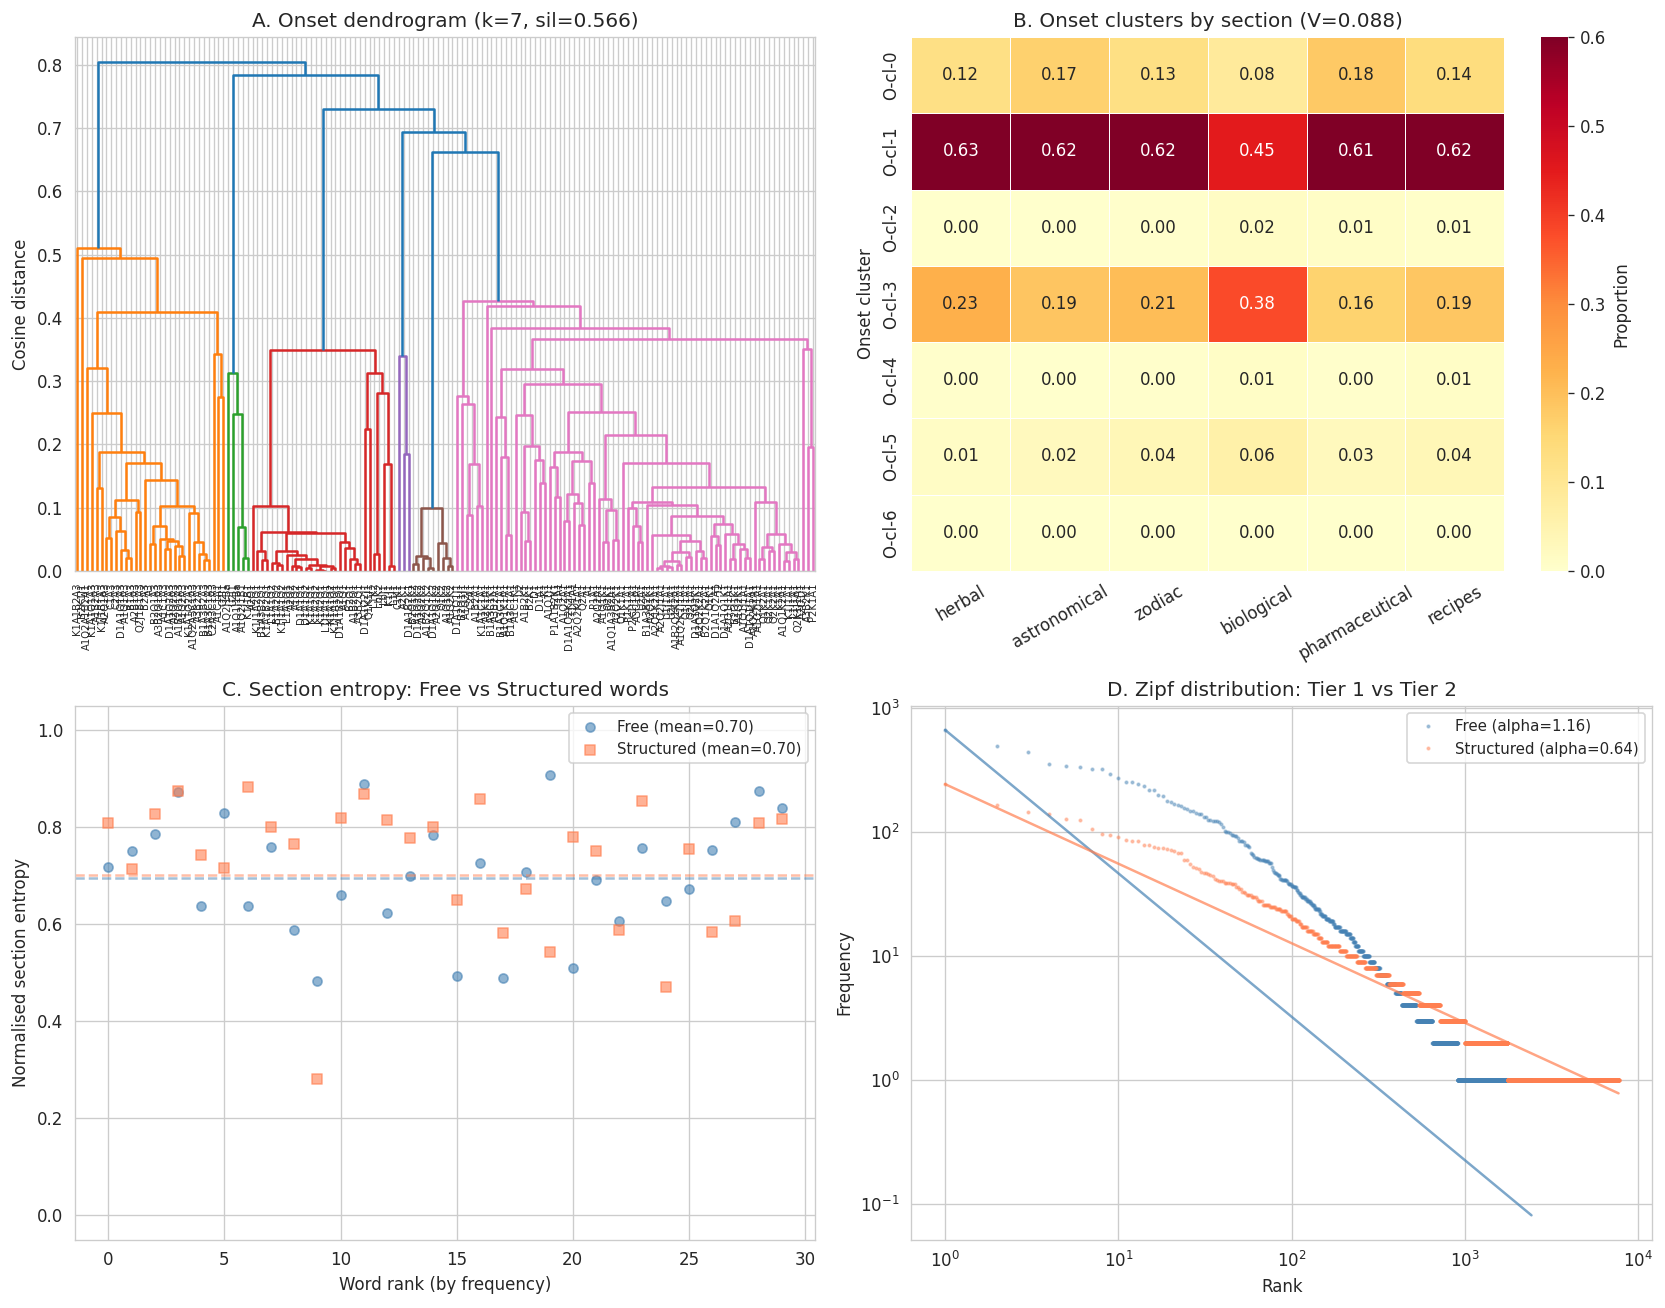

Saved: images/distributional_clustering.png


In [10]:
# ── Cell 11: Composite figure ────────────────────────────────────────
# 4-panel figure:
# 1. Onset cluster dendrogram
# 2. Onset clusters x sections heatmap
# 3. Section entropy: Free vs Structured
# 4. Zipf plots for Tier 1 vs Tier 2

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ── Panel 1: Onset dendrogram ──
ax1 = axes[0, 0]
onset_labels_str = [syl_str(s) for s in onsets_func]
# Color threshold from best clustering
dendrogram(onset_linkage, labels=onset_labels_str, ax=ax1,
           leaf_rotation=90, leaf_font_size=7,
           color_threshold=0.7 * max(onset_linkage[:, 2]))
ax1.set_title(f'A. Onset dendrogram (k={best_k_onset}, sil={best_sil_onset:.3f})')
ax1.set_ylabel('Cosine distance')
ax1.tick_params(axis='x', labelsize=6)

# ── Panel 2: Onset clusters x sections heatmap ──
ax2 = axes[0, 1]
sns.heatmap(onset_sec_norm, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=SECTIONS_ORDER,
            yticklabels=[f'O-cl-{i}' for i in range(n_onset_clusters)],
            ax=ax2, linewidths=0.5, vmin=0, vmax=0.6,
            cbar_kws={'label': 'Proportion'})
ax2.set_title(f'B. Onset clusters by section (V={v_onset:.3f})')
ax2.set_ylabel('Onset cluster')
ax2.set_xlabel('')
ax2.tick_params(axis='x', rotation=30)

# ── Panel 3: Section entropy comparison ──
ax3 = axes[1, 0]
positions = np.arange(len(top50_free[:30]))
ax3.scatter(positions, ent_free[:30], alpha=0.6, s=30, label=f'Free (mean={mean_ent_free:.2f})', c='steelblue')
positions2 = np.arange(len(top50_struct[:30]))
ax3.scatter(positions2, ent_struct[:30], alpha=0.6, s=30, label=f'Structured (mean={mean_ent_struct:.2f})', c='coral', marker='s')
ax3.axhline(mean_ent_free, color='steelblue', linestyle='--', alpha=0.5)
ax3.axhline(mean_ent_struct, color='coral', linestyle='--', alpha=0.5)
ax3.set_xlabel('Word rank (by frequency)')
ax3.set_ylabel('Normalised section entropy')
ax3.set_title('C. Section entropy: Free vs Structured words')
ax3.legend(fontsize=9)
ax3.set_ylim(-0.05, 1.05)

# ── Panel 4: Zipf plots ──
ax4 = axes[1, 1]
ax4.loglog(ranks_free, freqs_free, '.', alpha=0.4, markersize=3, color='steelblue',
           label=f'Free (alpha={alpha_free:.2f})')
ax4.loglog(ranks_struct, freqs_struct, '.', alpha=0.4, markersize=3, color='coral',
           label=f'Structured (alpha={alpha_struct:.2f})')
# Fit lines
ax4.loglog(ranks_free, np.exp(np.log(freqs_free[0]) - alpha_free * np.log(ranks_free)),
           '-', color='steelblue', alpha=0.7, linewidth=1.5)
ax4.loglog(ranks_struct, np.exp(np.log(freqs_struct[0]) - alpha_struct * np.log(ranks_struct)),
           '-', color='coral', alpha=0.7, linewidth=1.5)
ax4.set_xlabel('Rank')
ax4.set_ylabel('Frequency')
ax4.set_title('D. Zipf distribution: Tier 1 vs Tier 2')
ax4.legend(fontsize=9)

plt.tight_layout()
os.makedirs('images', exist_ok=True)
fig.savefig('images/distributional_clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/distributional_clustering.png')

## Conclusions

**Distributional clustering of onsets and codas** reveals the internal structure of the Voynich two-tier encoding without requiring any target-language assumption:

1. **Onset clusters**: The silhouette score and section-specificity (Cramer's V) indicate whether onsets group into meaningful "semantic families" that align with manuscript sections. A significant chi-squared and higher V for onsets than codas would support the onset=category hypothesis.

2. **Coda clusters**: If codas are more uniformly distributed across sections than onsets, they behave like modifiers/specifiers rather than category markers.

3. **Free words (Tier 1)**: Their Zipf exponent, section entropy, and bigram context reveal whether they function as grammatical particles (high entropy, appear between structured words) or as content words (section-specific, clustered).

4. **Two-tier encoding**: The combination of positional rigidity (from notebook 36), distributional clustering (this notebook), and the function-word analysis provides a comprehensive characterisation of the encoding mechanism that is **independent of any decipherment attempt**.

In [11]:
# ── Cell 13: Export results ───────────────────────────────────────────
results = {
    'metadata': {
        'notebook': '37_distributional_clustering',
        'corpus': 'STA1 2.0',
        'segmentation': 'TP-P20',
        'n_words': n_words,
        'n_glyph_tokens': n_tokens,
        'n_glyph_types': n_glyphs,
    },
    'cooccurrence_matrix': {
        'n_onsets_functional': len(onsets_func),
        'n_codas_functional': len(codas_func),
        'n_oc_pairs': len(oc_pairs),
        'matrix_density': float((cooc > 0).sum() / cooc.size),
        'total_cooccurrences': int(cooc.sum()),
    },
    'onset_clustering': {
        'best_k': best_k_onset,
        'silhouette': float(best_sil_onset),
        'silhouette_by_k': {str(k): float(v) for k, v in onset_sil_scores.items()},
        'pca_variance': [float(v) for v in pca_var_onset],
        'clusters': {
            str(cl): {
                'n_members': sum(1 for l in onset_labels if l == cl),
                'top_onsets': [syl_str(onsets_func[i]) for i in range(len(onsets_func))
                               if onset_labels[i] == cl][:5],
            }
            for cl in range(best_k_onset)
        },
    },
    'coda_clustering': {
        'best_k': best_k_coda,
        'silhouette': float(best_sil_coda),
        'silhouette_by_k': {str(k): float(v) for k, v in coda_sil_scores.items()},
        'pca_variance': [float(v) for v in pca_var_coda],
        'clusters': {
            str(cl): {
                'n_members': sum(1 for l in coda_labels if l == cl),
                'top_codas': [syl_str(codas_func[i]) for i in range(len(codas_func))
                              if coda_labels[i] == cl][:5],
            }
            for cl in range(best_k_coda)
        },
    },
    'section_analysis': {
        'onset_chi2': float(chi2_onset),
        'onset_p': float(p_onset),
        'onset_cramers_v': float(v_onset),
        'coda_chi2': float(chi2_coda),
        'coda_p': float(p_coda),
        'coda_cramers_v': float(v_coda),
        'onset_more_specific': bool(v_onset > v_coda),
    },
    'free_word_analysis': {
        'n_free_tokens': len(free_words),
        'n_free_types': len(free_freq),
        'n_struct_tokens': len(struct_words),
        'n_struct_types': len(struct_freq),
        'zipf_alpha_free': float(alpha_free),
        'zipf_alpha_struct': float(alpha_struct),
        'zipf_r2_free': float(r2_free),
        'zipf_r2_struct': float(r2_struct),
        'mean_section_entropy_free': float(mean_ent_free),
        'mean_section_entropy_struct': float(mean_ent_struct),
        'free_more_uniform': bool(mean_ent_free > mean_ent_struct),
        'sfs_trigram_observed': float(sfs_count / total_free_trigrams) if total_free_trigrams > 0 else 0.0,
        'sfs_trigram_expected': float(expected_sfs),
        'top10_free_words': [
            {'word': w, 'freq': free_freq[w],
             'section_entropy': float(section_entropy(free_section_counts, w))}
            for w in top50_free[:10]
        ],
    },
    'bigram_context': {
        'free_preceded_by_free': float(context_before['free']['free'] / sum(context_before['free'].values())),
        'free_preceded_by_struct': float(context_before['free']['structured'] / sum(context_before['free'].values())),
        'free_followed_by_free': float(context_after['free']['free'] / sum(context_after['free'].values())),
        'free_followed_by_struct': float(context_after['free']['structured'] / sum(context_after['free'].values())),
    },
}

out_path = 'resultados/distributional_clustering_resultados.json'
os.makedirs('resultados', exist_ok=True)
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print(f'Results saved to {out_path}')
print(f'Keys: {list(results.keys())}')

Results saved to resultados/distributional_clustering_resultados.json
Keys: ['metadata', 'cooccurrence_matrix', 'onset_clustering', 'coda_clustering', 'section_analysis', 'free_word_analysis', 'bigram_context']
